In [1]:
#202431077_Siti Shafira Shafarina.A
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#202431077_Siti Shafira Shafarina.A
# 1. Membaca dataset Excel
raw = pd.read_excel("20_Jumlah_Produksi_Kelapa.xlsx",
                    header=None)

In [3]:
#202431077_Siti Shafira Shafarina.A
# Mengambil nama provinsi dan produksi tahun 2024
df = raw.iloc[10:48, [1, 6]].copy()
df.columns = ["Provinsi", "Produksi_2024"]

In [4]:
#202431077_Siti Shafira Shafarina.A
# Membersihkan data
df["Provinsi"] = df["Provinsi"].astype(str).str.strip()
df["Produksi_2024"] = pd.to_numeric(
    df["Produksi_2024"].replace("-", np.nan),
    errors="coerce"
)
df = df.dropna(subset=["Produksi_2024"])


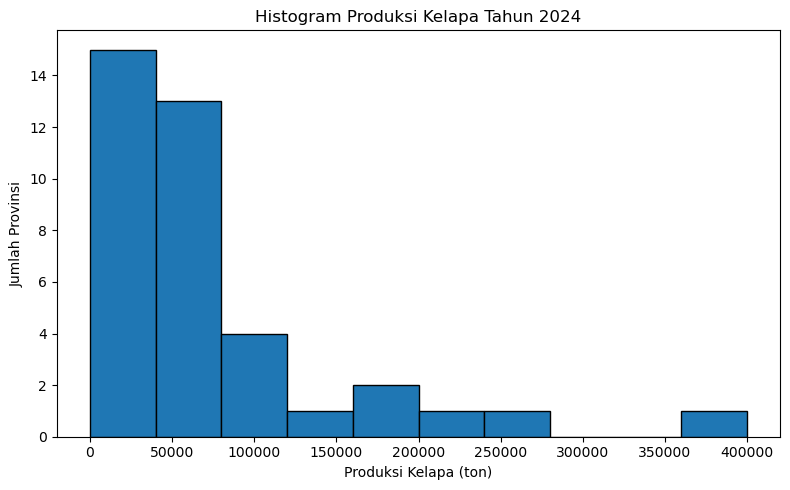

In [5]:
#202431077_Siti Shafira Shafarina.A
# 2. Histogram
plt.figure(figsize=(8, 5))
plt.hist(df["Produksi_2024"], bins=10, edgecolor="black")
plt.title("Histogram Produksi Kelapa Tahun 2024")
plt.xlabel("Produksi Kelapa (ton)")
plt.ylabel("Jumlah Provinsi")
plt.tight_layout()
plt.savefig("histogram_produksi_kelapa.png", dpi=300)
plt.show()

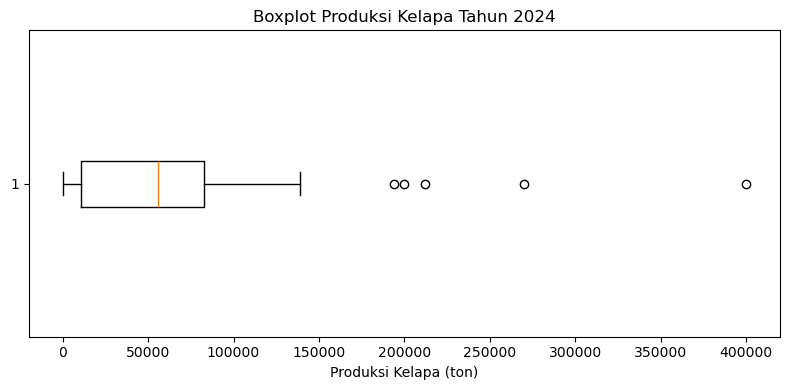

In [6]:
#202431077_Siti Shafira Shafarina.A
# 3. Boxplot
plt.figure(figsize=(8, 4))
plt.boxplot(df["Produksi_2024"], vert=False)
plt.title("Boxplot Produksi Kelapa Tahun 2024")
plt.xlabel("Produksi Kelapa (ton)")
plt.tight_layout()
plt.savefig("boxplot_produksi_kelapa.png", dpi=300)
plt.show()

In [7]:
#202431077_Siti Shafira Shafarina.A
# 4. Statistik untuk mendukung pembahasan
print(df["Produksi_2024"].describe())

Q1 = df["Produksi_2024"].quantile(0.25)
Q3 = df["Produksi_2024"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

print("\nCalon outlier:")
print(df[
    (df["Produksi_2024"] < batas_bawah) |
    (df["Produksi_2024"] > batas_atas)
])


count        38.000000
mean      72066.436974
std       85081.696173
min           0.000000
25%       10406.467500
50%       55861.885000
75%       82585.657250
max      399953.876320
Name: Produksi_2024, dtype: float64
Q1: 10406.467499999999
Q3: 82585.65725000002
IQR: 72179.18975000002
Batas bawah: -97862.31712500003
Batas atas: 190854.44187500005

Calon outlier:
           Provinsi  Produksi_2024
13             Riau  399953.876320
24       Jawa Timur  194141.638030
34   Sulawesi Utara  270301.988002
35  Sulawesi Tengah  199639.153370
41     Maluku Utara  212094.220000
